# Evidence for performance optimization

Analyze the existing 25-pipeline trajectory without replaying pipelines or profiling. Run all cells from the repository root using the project Python environment. Helpers are embedded; pre-generated analysis CSVs are not required.

Tables and charts are computed deterministically. The English interpretations are written by the assistant after reviewing the executed tables, source evidence and chart images. They describe the reviewed run and must be refreshed after input or code changes; there is no API dependency or automatic LLM call.

Existing category statistics are exploratory and have not been independently audited. Single-run sampling does not establish stable bottlenecks. Source equivalence does not establish cache compatibility. Simulations and Amdahl curves are assumptions, not measured speedups.


## 1. Data scope and environment

**Objective:** Establish pipeline coverage, step membership and evidence provenance.

**Data and method:** Read the manifest, existing category CSV and profiles. Keep trace, prediction and execution-summary evidence separate.


In [1]:
from __future__ import annotations
import ast
from collections import defaultdict
import hashlib
import json
import os
from pathlib import Path
import tempfile

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'deai-matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd().resolve()
if not (ROOT / 'spaceship_titanic_students/trajectory.json').is_file():
    raise FileNotFoundError('Start the notebook kernel in the deai-pro repository root.')
root = ROOT
trajectory = 'spaceship_titanic_students'
CATEGORIES = ['setup', 'data handling', 'models', 'other']
CPU = {'python_s': 'n_cpu_percent_python', 'native_s': 'n_cpu_percent_c', 'system_s': 'n_sys_percent'}
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda value: f'{value:.4f}')
output = root / 'results' / trajectory / 'bottleneck_analysis' / 'notebook'

manifest = json.loads((root / trajectory / 'trajectory.json').read_text())
steps = {Path(p['file']).stem: step['step'] for step in manifest['steps'] for p in step['pipelines']}
if len(steps) != sum(len(step['pipelines']) for step in manifest['steps']):
    raise ValueError('Duplicate pipeline IDs in manifest')
categories = pd.read_csv(root / 'results' / trajectory / 'categories.csv')
categories = categories[categories.pipeline.isin(steps)].copy()
if set(categories.pipeline) != set(steps):
    raise ValueError('Categories do not cover every manifest pipeline')
profiles = {p: json.loads((root / 'profiles' / trajectory / f'{p}.json').read_text()) for p in steps}
pipelines = pd.DataFrame([
    dict(pipeline=p, step=steps[p], elapsed_time_sec=data['elapsed_time_sec'],
         max_footprint_mb=data['max_footprint_mb'], source=f'profiles/{trajectory}/{p}.json')
    for p, data in profiles.items()
])
# Verify that notebook execution preserves inputs; not a performance metric audit.
input_paths = [root / trajectory / 'trajectory.json', root / 'results' / trajectory / 'categories.csv']
input_paths += list((root / 'profiles' / trajectory).glob('*.json'))
input_paths += list((root / 'libraries' / trajectory).glob('*.json'))
input_paths += list((root / trajectory).glob('pipeline_*.py'))
input_paths += list((root / trajectory / 'results').rglob('*.csv'))
input_paths += [root / trajectory / 'results/summary.json']
input_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in input_paths}
display(pipelines.groupby('step').agg(pipelines=('pipeline', 'count')))
# Detect when the reviewed prose no longer describes the current inputs or code.
review_notebook = json.loads((root / 'analyze_bottlenecks.ipynb').read_text())
review_fingerprint = hashlib.sha256(json.dumps({
    'inputs': {str(path.relative_to(root)): digest for path, digest in input_hashes.items()},
    'code': [''.join(cell['source']) for cell in review_notebook['cells'] if cell['cell_type'] == 'code'],
}, sort_keys=True).encode()).hexdigest()
review_current = review_fingerprint == review_notebook.get('metadata', {}).get('evidence_review', {}).get('fingerprint')
display(Markdown('**Review status:** Evidence and code match the reviewed snapshot.' if review_current else
    '**STALE REVIEW:** Inputs or analysis code changed. Refresh the assistant-written interpretations before using them for decisions.'))


,pipelines
step,
1,3
2,3
3,3
4,5
5,4
6,4
7,3


**Review status:** Evidence and code match the reviewed snapshot.

**Reviewed interpretation — scope.** The evidence covers 25 pipelines in seven steps and 100 existing category records. Profile timings, library-call traces and prediction artifacts are separate observations. Their common pipeline names allow exploration, but do not establish a shared historical execution identity.


## 2. Trajectory runtime and pipeline contribution

**Objective:** Determine whether costs are concentrated in individual pipelines or shared stages.

**Data and method:** Sum existing category attribution and divide by total profile elapsed time; rank pipelines and calculate cumulative contribution.


,category,total_s,denominator_profile_s,share_of_profile_elapsed,coverage_pipelines
0,setup,25.5978,75.0710,0.3410,25
1,data handling,9.3286,75.0710,0.1243,25
2,models,38.7141,75.0710,0.5157,25
3,other,0.9269,75.0710,0.0123,25


,pipeline,step,elapsed_time_sec,share,cumulative_share
0,pipeline_6_2,6,4.8994,0.0653,0.0653
1,pipeline_7_3,7,4.4475,0.0592,0.1245
2,pipeline_6_1,6,4.4422,0.0592,0.1837
3,pipeline_6_3,6,4.2889,0.0571,0.2408
4,pipeline_5_3,5,4.2578,0.0567,0.2975
5,pipeline_7_1,7,4.2368,0.0564,0.3540
6,pipeline_7_2,7,4.1935,0.0559,0.4098
7,pipeline_6_4,6,3.5595,0.0474,0.4572
8,pipeline_4_3,4,3.3213,0.0442,0.5015
9,pipeline_5_2,5,3.2630,0.0435,0.5449


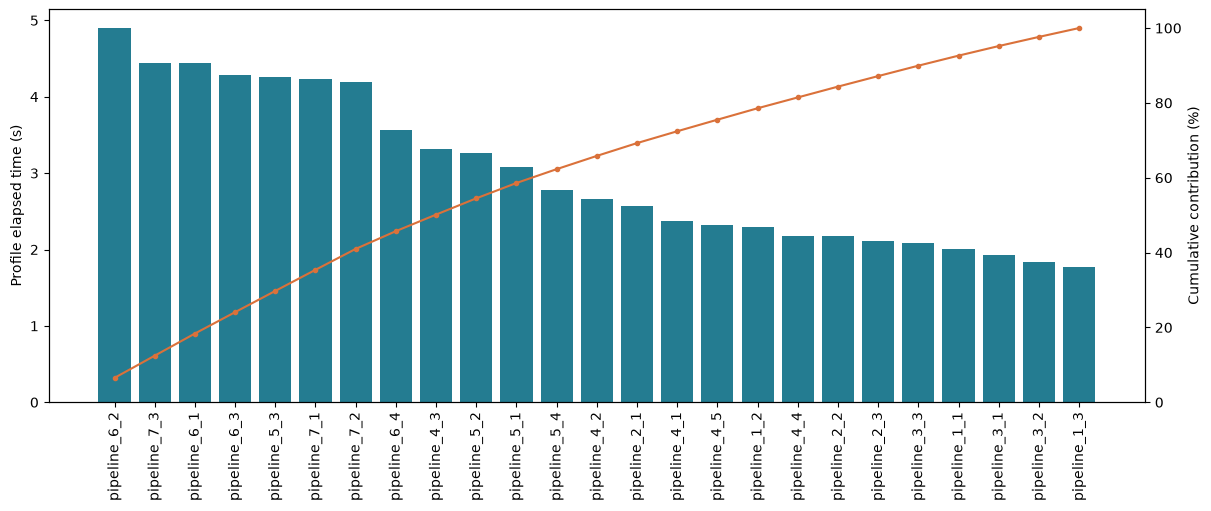

In [2]:
ranking = pipelines.sort_values('elapsed_time_sec', ascending=False).reset_index(drop=True)
total = pipelines.elapsed_time_sec.sum()
ranking['share'] = ranking.elapsed_time_sec / total
ranking['cumulative_share'] = ranking.share.cumsum()
categories['step'] = categories.pipeline.map(steps)
totals = categories.groupby('category', sort=False).total_s.sum().reindex(CATEGORIES).reset_index()
totals['denominator_profile_s'] = total
totals['share_of_profile_elapsed'] = totals.total_s / total
totals['coverage_pipelines'] = len(pipelines)
count80 = int((ranking.cumulative_share < .8).sum()) + 1
display(totals)
display(ranking[['pipeline', 'step', 'elapsed_time_sec', 'share', 'cumulative_share']])
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
ax.bar(ranking.pipeline, ranking.elapsed_time_sec, color='#247c91')
ax.tick_params(axis='x', rotation=90)
ax.set_ylabel('Profile elapsed time (s)')
right = ax.twinx()
right.plot(ranking.pipeline, ranking.cumulative_share * 100, color='#da713a', marker='.')
right.set_ylabel('Cumulative contribution (%)')
right.set_ylim(0, 105)
figures = {'pipeline_ranking': fig}
display(fig)
plt.close(fig)

**Reviewed interpretation — runtime distribution.** Total profile elapsed time is 75.071 seconds. Existing attribution assigns 38.714 seconds (51.6%) to model-related work, 25.598 seconds (34.1%) to setup, and 9.329 seconds (12.4%) to data handling. These categories do not exhaust the elapsed denominator. Eighteen pipelines are needed to reach 80% of total elapsed time, so the opportunity is distributed rather than concentrated in a single outlier. This favors investigating common overhead and repeated computation alongside individual hotspots. The timings include profiling overhead.


## 3. Performance composition by step

**Objective:** Compare early baseline steps with later model and blending steps.

**Data and method:** Aggregate elapsed time and categories by manifest step. Use each step's elapsed total as its denominator.


,step,pipelines,total_s,mean_s,ideal_step_s,largest_observed_process_peak_mb
0,1,3,6.0845,2.0282,2.2948,101.1401
1,2,3,6.8503,2.2834,2.5682,117.0355
2,3,3,5.8472,1.9491,2.0874,118.9744
3,4,5,12.8470,2.5694,3.3213,119.1728
4,5,4,13.3743,3.3436,4.2578,128.8298
5,6,4,17.1899,4.2975,4.8994,128.5035
6,7,3,12.8778,4.2926,4.4475,127.7205


,step,category,total_s,denominator_profile_s,share_of_step_profile_elapsed
0,1,data handling,0.9776,6.0845,0.1607
1,1,models,0.5022,6.0845,0.0825
2,1,other,0.1535,6.0845,0.0252
3,1,setup,4.3947,6.0845,0.7223
4,2,data handling,1.3597,6.8503,0.1985
5,2,models,0.4649,6.8503,0.0679
6,2,other,0.2073,6.8503,0.0303
7,2,setup,4.8003,6.8503,0.7007
8,3,data handling,1.4807,5.8472,0.2532
9,3,models,0.3190,5.8472,0.0546


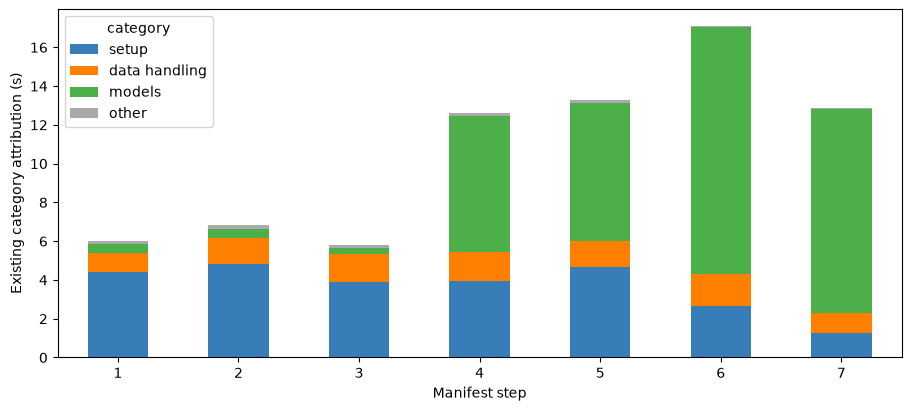

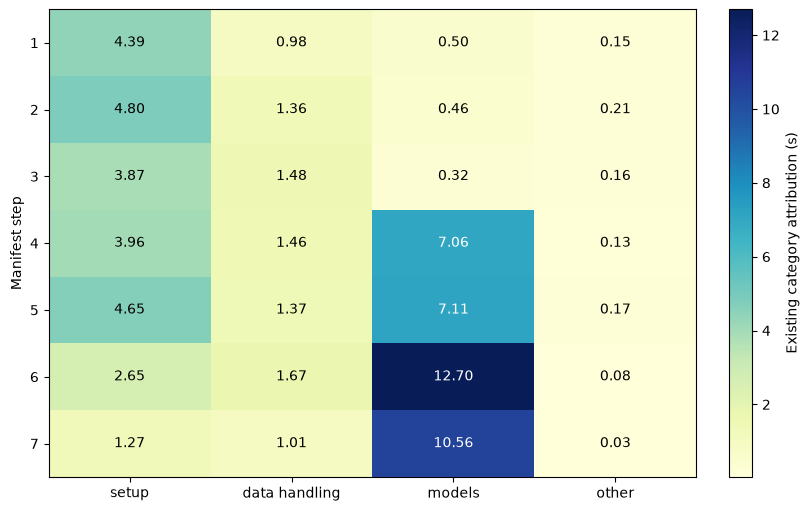

In [3]:
summary = pipelines.groupby('step').agg(pipelines=('pipeline', 'count'), total_s=('elapsed_time_sec', 'sum'),
                                      mean_s=('elapsed_time_sec', 'mean'), ideal_step_s=('elapsed_time_sec', 'max'),
                                      largest_observed_process_peak_mb=('max_footprint_mb', 'max'))
composition = categories.pivot_table(index='step', columns='category', values='total_s', aggfunc='sum').reindex(columns=CATEGORIES)
step_categories = categories.groupby(['step', 'category'], as_index=False).total_s.sum()
step_categories['denominator_profile_s'] = step_categories.step.map(summary.total_s)
step_categories['share_of_step_profile_elapsed'] = step_categories.total_s / step_categories.denominator_profile_s
display(summary.reset_index())
display(step_categories)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
composition.plot.bar(stacked=True, ax=ax, color=['#377eb8', '#ff7f00', '#4daf4a', '#aaa'])
ax.set_ylabel('Existing category attribution (s)')
ax.set_xlabel('Manifest step')
ax.tick_params(axis='x', rotation=0)
figures['step_categories'] = fig
display(fig)
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
img = ax.imshow(composition.values, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(len(composition.columns)), composition.columns)
ax.set_yticks(range(len(composition.index)), composition.index)
ax.set_ylabel('Manifest step')
for i in range(len(composition)):
    for j in range(len(composition.columns)):
        ax.text(j, i, f'{composition.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if composition.iloc[i, j] > composition.values.max() * .55 else 'black')
fig.colorbar(img, ax=ax, label='Existing category attribution (s)')
figures['step_heatmap'] = fig
display(fig)
plt.close(fig)

**Reviewed interpretation — step composition.** The stacked bars and heatmap show setup dominating steps 1–3, while model-related costs dominate the later blending and threshold steps. Step 6 has the largest aggregate elapsed time (17.190 seconds), followed by steps 5 and 7. Total step time also depends on candidate count, so it is not a measure of per-pipeline efficiency. The step-specific pattern argues for startup experiments on early steps and training/reuse experiments on later steps.


## 4. Code regions, hotspots and helpers

**Objective:** Locate sampled costs in source code and distinguish Python, native and system components.

**Data and method:** Match profile line text to current source; assign AST regions and helper ownership once. Unresolved samples remain missing, not zero.


### Analysis helpers

These functions parse existing source and records without executing pipelines.

In [4]:
def signature(nodes):
    """Ignore locations/formatting, preserve constants, arguments and statement order."""
    return hashlib.sha256('\n'.join(ast.dump(n, include_attributes=False) for n in nodes).encode()).hexdigest()


def assigned(node, name):
    return isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == name for t in node.targets)


def span(nodes):
    return sorted({line for n in nodes for line in range(n.lineno, n.end_lineno + 1)})


def source_matches(recorded, current):
    # Existing Scalene JSON stores HTML-safe escapes literally in line text.
    # Encode the known current text instead of broadly decoding Python escapes.
    escaped = current
    for char, escape in [('&', r'\u0026'), ('<', r'\u003c'), ('>', r'\u003e')]:
        escaped = escaped.replace(char, escape)
    return recorded.strip() in {current.strip(), escaped.strip()}


class CanonicalOutputs(ast.NodeTransformer):
    def visit_Name(self, node):
        if node.id.startswith(('val_', 'test_')) and node.id.rsplit('_', 1)[-1].isdigit():
            return ast.copy_location(ast.Name(id=node.id.split('_')[0] + '_output', ctx=node.ctx), node)
        return node


def inspect_source(path):
    """Recognize this trajectory's explicit straight-line main + CV blocks conservatively."""
    source = path.read_text()
    tree = ast.parse(source)
    main = next(n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name == 'main')
    body = main.body
    cv = next(n for n in body if isinstance(n, ast.For) and 'splitter.split' in ast.unparse(n.iter))
    feature_start = next(n.lineno for n in body if assigned(n, 'manifest'))
    cat_index = next(i for i, n in enumerate(body) if assigned(n, 'cat_cols'))
    split_start = next(n.lineno for n in body if assigned(n, 'splitter'))
    write_start = next(n.lineno for n in body if assigned(n, 'destination'))
    owners = {}
    for n in tree.body:
        if isinstance(n, (ast.Import, ast.ImportFrom)):
            for line in span([n]):
                owners[line] = 'Initialization'
    for line in range(main.lineno + 1, main.end_lineno + 1):
        owners[line] = ('Reading and validation' if line < feature_start else
                        'Feature engineering (including helpers)' if line < split_start else
                        'Cross-validation splitting' if line <= cv.lineno else
                        'Prediction, blending and scoring' if line < write_start else 'Output writing')
    for n in cv.body:
        text = ast.unparse(n)
        region = ('Preprocessing fit and transform' if assigned(n, 'preprocessor') or 'preprocessor.' in text else
                  'Model fitting' if assigned(n, 'classifier') or 'classifier.fit(' in text else
                  'Prediction, blending and scoring')
        for line in span([n]):
            owners[line] = region
    helpers = {}
    for helper in (n for n in ast.walk(main) if isinstance(n, ast.FunctionDef) and n is not main):
        callers = sorted({n.lineno for n in ast.walk(main)
                          if isinstance(n, ast.Name) and isinstance(n.ctx, ast.Load) and n.id == helper.name})
        caller_regions = {owners.get(line, 'Unmatched or other') for line in callers}
        region = next(iter(caller_regions)) if len(caller_regions) == 1 else 'Shared helper (unresolved ownership)'
        for line in span([helper]):
            owners[line] = region
            helpers[line] = f'{helper.name}; callers={",".join(map(str, callers))}'
    imports = [n for n in tree.body if isinstance(n, (ast.Import, ast.ImportFrom))]
    # Include imported bindings as an explicit semantic precondition, not a hash of
    # the whole import list: blends import extra estimators without changing pandas.
    bindings = {}
    for n in imports:
        for a in n.names:
            bindings[a.asname or a.name.split('.')[0]] = (getattr(n, 'module', None), a.name)

    def key(nodes, dependencies=()):
        used = {n.id for item in [*dependencies, *nodes] for n in ast.walk(item) if isinstance(n, ast.Name)}
        env = sorted((name, bindings[name]) for name in used if name in bindings)
        return signature([*dependencies, *nodes]) + json.dumps(env, sort_keys=True)

    prefix = body[:body.index(cv)]
    read_nodes = [n for n in body if n.lineno < feature_start]
    feature_nodes = [n for n in body[:cat_index] if n.lineno >= feature_start]
    candidates = [('Reading and validation', key(read_nodes), span(read_nodes), 'Matching input paths, validation, labels and row order; historical file identity unknown'),
                  ('Feature engineering', key(feature_nodes, read_nodes), span(feature_nodes), 'Includes helpers; matching inputs and processing rules; identical statements determine columns and row order')]
    prep_starts = [i for i, n in enumerate(cv.body) if assigned(n, 'preprocessor')]
    for j, start in enumerate(prep_starts):
        end = prep_starts[j + 1] if j + 1 < len(prep_starts) else len(cv.body)
        block = cv.body[start:end]
        model_i = next(i for i, n in enumerate(block) if assigned(n, 'classifier'))
        prep = block[:model_i]
        model = []
        for n in block[model_i:]:
            if assigned(n, 'classifier') or any(isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                                               and isinstance(c.func.value, ast.Name) and c.func.value.id == 'classifier'
                                               for c in ast.walk(n)):
                model.append(n)
            else:
                break
        canonical = [CanonicalOutputs().visit(ast.parse(ast.unparse(n)).body[0]) for n in model]
        fold_dep = ast.Expr(value=cv.iter)
        candidates.append(('Within-fold preprocessing', key(prep, [*prefix, fold_dep]), span(prep),
                           'Matching feature prefix, columns, labels, splitter, fold rows, transformers and parameters'))
        candidates.append(('Model training and prediction', key(canonical, [*prefix, fold_dep, *prep]), span(model),
                           'Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probability variable names normalized'))
    # Threshold/blend family is a separate overlapping alternative; no savings added.
    probability_nodes = []
    for n in cv.body:
        if assigned(n, 'score'):
            break
        probability_nodes.append(n)
    candidates.append(('Upstream probabilities for threshold variants', key(probability_nodes, prefix), span(probability_nodes),
                       'Matching probability generation, blend weights and accumulation; scoring thresholds and output paths excluded'))
    return source.splitlines(), owners, helpers, candidates


def line_records(root, trajectory, pipeline, step, source_info):
    source, owners, helpers, _ = source_info
    pp = root / 'profiles' / trajectory / f'{pipeline}.json'
    tp = root / 'libraries' / trajectory / f'{pipeline}.json'
    profile, trace = json.loads(pp.read_text()), json.loads(tp.read_text())
    elapsed = profile['elapsed_time_sec']
    rows = []
    seen = set()
    for filename, detail in profile['files'].items():
        is_main = filename == profile['program']
        for record in detail['lines']:
            line = record['lineno']
            identity = (filename, line)
            if identity in seen:
                raise ValueError(f'Duplicate profile line: {pipeline} {identity}')
            seen.add(identity)
            match = is_main and 0 < line <= len(source) and source_matches(record['line'], source[line - 1])
            components = {name: record.get(field, 0) * elapsed / 100 for name, field in CPU.items()}
            total = sum(components.values())
            modules = trace.get('lines', {}).get(str(line), {}) if match else {}
            rows.append(dict(pipeline=pipeline, step=step, profile_file=str(pp.relative_to(root)),
                             trace_file=str(tp.relative_to(root)), profile_source=filename,
                             source_file=f'{trajectory}/{pipeline}.py' if match else '', line=line,
                             code=source[line - 1].strip() if match else record['line'].strip(),
                             profile_line_raw=record['line'].rstrip(), source_matched=match,
                             region=owners.get(line, 'Unmatched or other') if match else 'Unmatched or other',
                             helper=helpers.get(line, '') if match else '',
                             attribution_s=total if total > 0 else None, **components,
                             status='Observed sample attribution' if total > 0 else
                             'Call observed in separate trace; profile time unresolved' if modules else 'Time unresolved',
                             trace_modules=json.dumps(modules, ensure_ascii=False, sort_keys=True),
                             peak_mb=record.get('n_peak_mb', 0), malloc_mb=record.get('n_malloc_mb', 0),
                             copy_mb_s_raw=record.get('n_copy_mb_s', 0),
                             confidence='Current source text matches; historical execution identity unverified' if match else 'Cannot match current source'))
    # A trace-only line is retained without inventing a profile observation.
    existing = {r['line'] for r in rows if r['profile_source'] == profile['program']}
    for line, modules in trace.get('lines', {}).items():
        line = int(line)
        if line not in existing:
            rows.append(dict(pipeline=pipeline, step=step, line=line, region='Unmatched or other',
                             source_matched=False, profile_file=str(pp.relative_to(root)),
                             trace_file=str(tp.relative_to(root)), profile_source='trace-only',
                             code='', source_file='', helper='', attribution_s=None,
                             status='Call observed in separate trace; profile time unresolved',
                             trace_modules=json.dumps(modules, sort_keys=True),
                             confidence='Trace has no source snapshot; current line mapping is uncertain'))
    return rows, profile

In [5]:
infos, records = {}, []
for pipeline, step in steps.items():
    info = inspect_source(root / trajectory / f'{pipeline}.py')
    infos[pipeline] = info
    rows, _ = line_records(root, trajectory, pipeline, step, info)
    records.extend(rows)
lines = pd.DataFrame(records)
regions = lines.groupby(['pipeline', 'step', 'region'], as_index=False).agg(
    attribution_s=('attribution_s', lambda s: s.sum(min_count=1)), python_s=('python_s', 'sum'),
    native_s=('native_s', 'sum'), system_s=('system_s', 'sum'), peak_mb=('peak_mb', 'max'),
    malloc_mb=('malloc_mb', 'sum'), copy_mb_s_raw_sum=('copy_mb_s_raw', 'sum'),
    sampled_lines=('attribution_s', 'count'), lines=('line', 'count'))
regions['status'] = regions.attribution_s.map(lambda x: 'Time unresolved' if pd.isna(x) else 'Sample attribution; not independently timed stages')
hotspots = lines[lines.attribution_s.notna()].sort_values('attribution_s', ascending=False)
conclusions = []
for p in steps:
    subset = regions[(regions.pipeline == p) & regions.attribution_s.notna()].sort_values('attribution_s', ascending=False)
    top = subset.iloc[0] if len(subset) else None
    conclusions.append(dict(pipeline=p, step=steps[p], top_region=top.region if top is not None else 'Insufficient evidence',
                            attributed_s=top.attribution_s if top is not None else None,
                            conclusion='Largest attributed region in one profile; stability unverified' if top is not None else 'Insufficient evidence',
                            evidence=f'line_attribution.csv: pipeline={p}; regions.csv'))
conclusions = pd.DataFrame(conclusions)
region_totals = regions.groupby('region')[['attribution_s', 'python_s', 'native_s', 'system_s']].sum(min_count=1).sort_values('attribution_s', ascending=False)


### 4.1. Sampled time by pipeline and region
Rows follow manifest steps. White separators mark step boundaries. Gray cells mean unresolved or absent attribution, not zero cost. Values are sampled seconds, not independently timed stages.

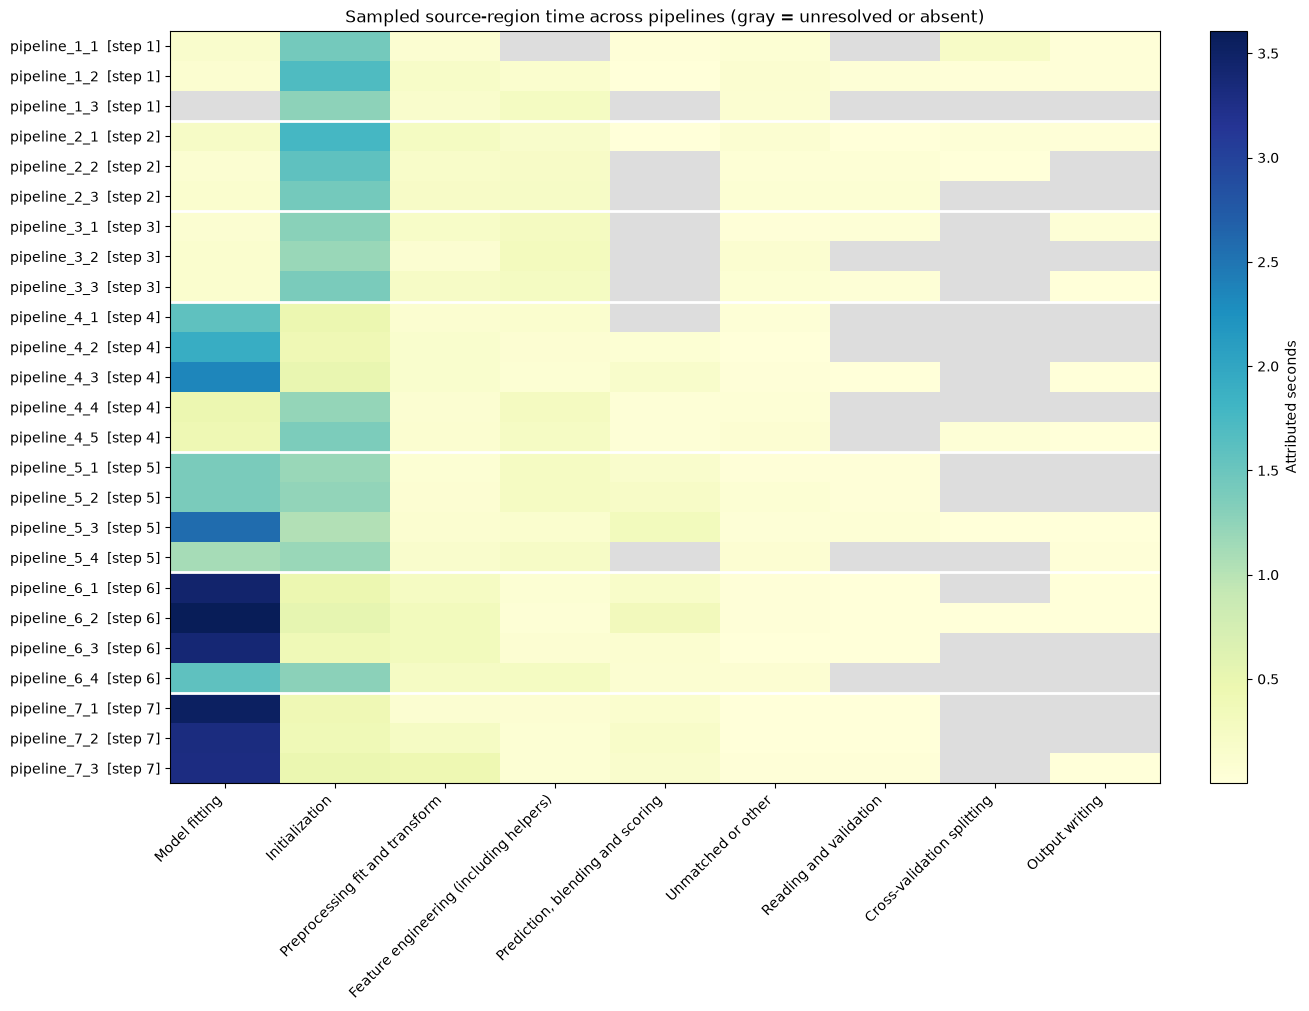

In [6]:
region_order = region_totals.index.tolist()
pipeline_order = pipelines.sort_values(['step', 'pipeline']).pipeline.tolist()
region_matrix = regions.pivot(index='pipeline', columns='region', values='attribution_s').reindex(index=pipeline_order, columns=region_order)
fig, ax = plt.subplots(figsize=(13, 10), layout='constrained')
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('#dddddd')
img = ax.imshow(region_matrix.to_numpy(dtype=float), aspect='auto', cmap=cmap)
ax.set_xticks(range(len(region_order)), region_order, rotation=45, ha='right')
ax.set_yticks(range(len(pipeline_order)), [f'{p}  [step {steps[p]}]' for p in pipeline_order])
for i in range(1, len(pipeline_order)):
    if steps[pipeline_order[i]] != steps[pipeline_order[i-1]]:
        ax.axhline(i-.5, color='white', linewidth=2)
ax.set_title('Sampled source-region time across pipelines (gray = unresolved or absent)')
fig.colorbar(img, ax=ax, label='Attributed seconds')
figures['region_heatmap'] = fig
display(fig)
plt.close(fig)

### 4.2. Execution components by region
Regions are ranked by total sampled attribution. Each bar separates Python, native and system components; labels show total seconds.

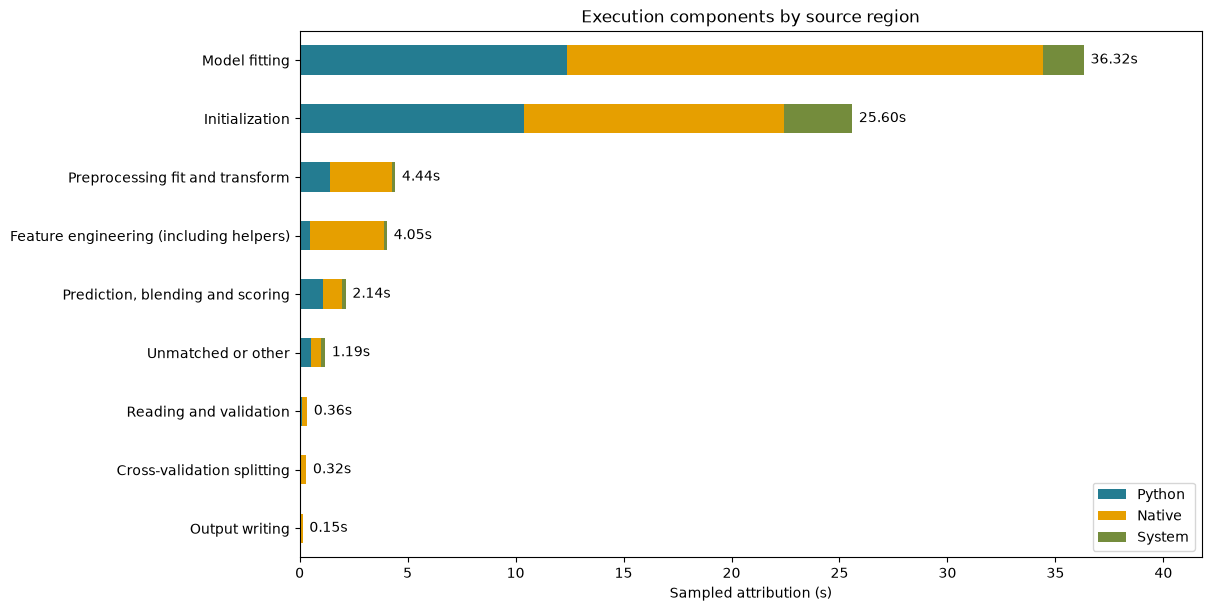

In [7]:
component_columns = ['python_s', 'native_s', 'system_s']
component_colors = ['#247c91', '#e69f00', '#748c3c']
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
region_totals[component_columns].plot.barh(stacked=True, ax=ax, color=component_colors)
ax.invert_yaxis()
for i, value in enumerate(region_totals.attribution_s):
    ax.text(value+.3, i, f'{value:.2f}s', va='center')
ax.set_xlim(0, region_totals.attribution_s.max()*1.15)
ax.set_xlabel('Sampled attribution (s)')
ax.set_ylabel('')
ax.set_title('Execution components by source region')
ax.legend(['Python', 'Native', 'System'], loc='lower right')
figures['region_components'] = fig
display(fig)
plt.close(fig)

### 4.3. Top sampled source lines
The top 15 sampled records are ranked by attributed seconds. The source table preserves full code text and the profile source path. A call-site attribution includes work inside the called library.

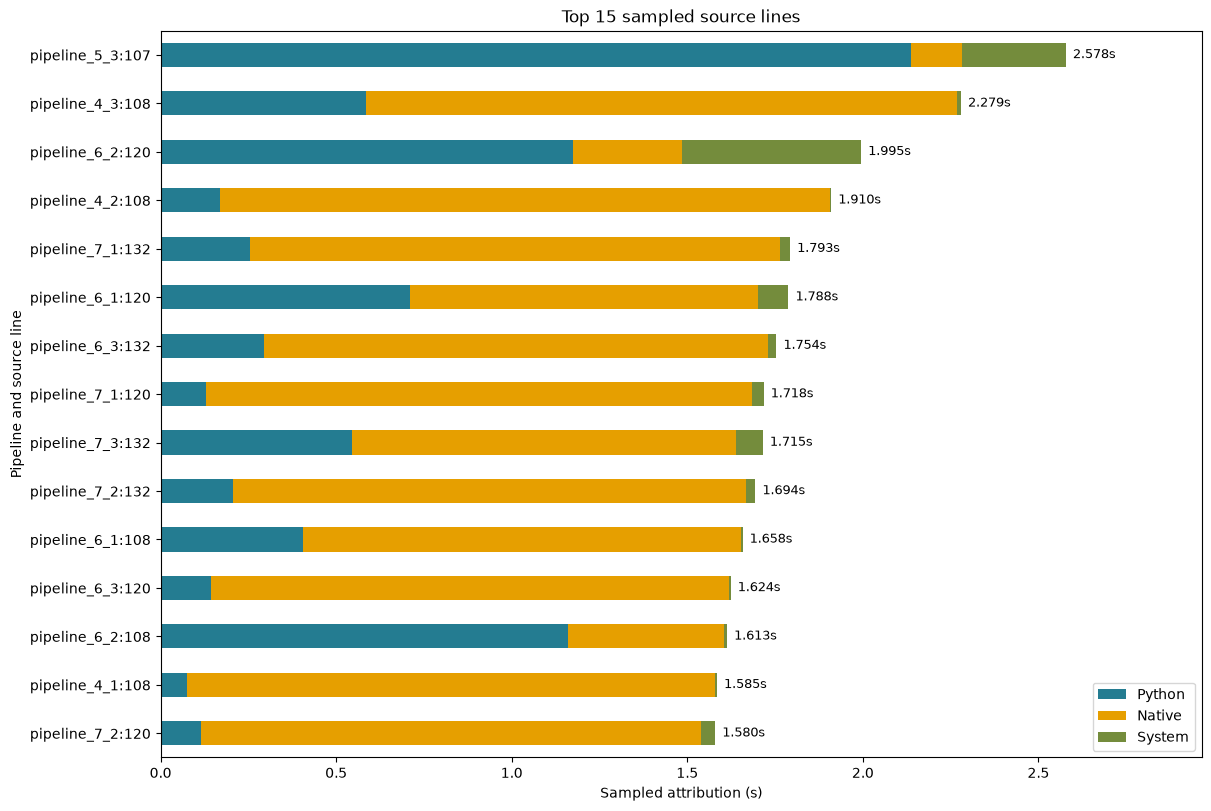

,source_label,region,code
0,pipeline_5_3:107,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
1,pipeline_4_3:108,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
2,pipeline_6_2:120,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
3,pipeline_4_2:108,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
4,pipeline_7_1:132,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
5,pipeline_6_1:120,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
6,pipeline_6_3:132,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
7,pipeline_7_1:120,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
8,pipeline_7_3:132,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"
9,pipeline_7_2:132,Model fitting,"classifier.fit(X_train_fold, y[fit_rows])"


In [8]:
top_source_lines = hotspots.head(15).copy()
top_source_lines['source_label'] = top_source_lines.apply(
    lambda row: f"{row.pipeline}:{int(row.line)}" if row.source_matched else f"{row.pipeline} | {row.profile_source}:{int(row.line)}", axis=1)
fig, ax = plt.subplots(figsize=(12, 8), layout='constrained')
top_source_lines.set_index('source_label')[component_columns].plot.barh(stacked=True, ax=ax, color=component_colors)
ax.invert_yaxis()
for i, value in enumerate(top_source_lines.attribution_s):
    ax.text(value+.02, i, f'{value:.3f}s', va='center', fontsize=9)
ax.set_xlim(0, top_source_lines.attribution_s.max()*1.15)
ax.set_xlabel('Sampled attribution (s)')
ax.set_ylabel('Pipeline and source line')
ax.set_title('Top 15 sampled source lines')
ax.legend(['Python', 'Native', 'System'], loc='lower right')
figures['top_source_lines'] = fig
display(fig)
plt.close(fig)
source_reference = top_source_lines[['source_label', 'region', 'code', 'profile_source', 'attribution_s']].reset_index(drop=True)
with pd.option_context('display.max_colwidth', None):
    display(source_reference[['source_label', 'region', 'code']])

### 4.4. Helper attribution and sampling coverage
Left: sampled time on helper body lines versus other lines in the same region. This is a partition of existing line records, not independent inclusive/exclusive call timing. Missing group times remain missing in the exported table; a missing bar segment means no resolved samples.

Right: record counts by evidence status. Trace-only evidence comes from a separate execution. These counts describe recorded lines, not the percentage of actual execution time captured.

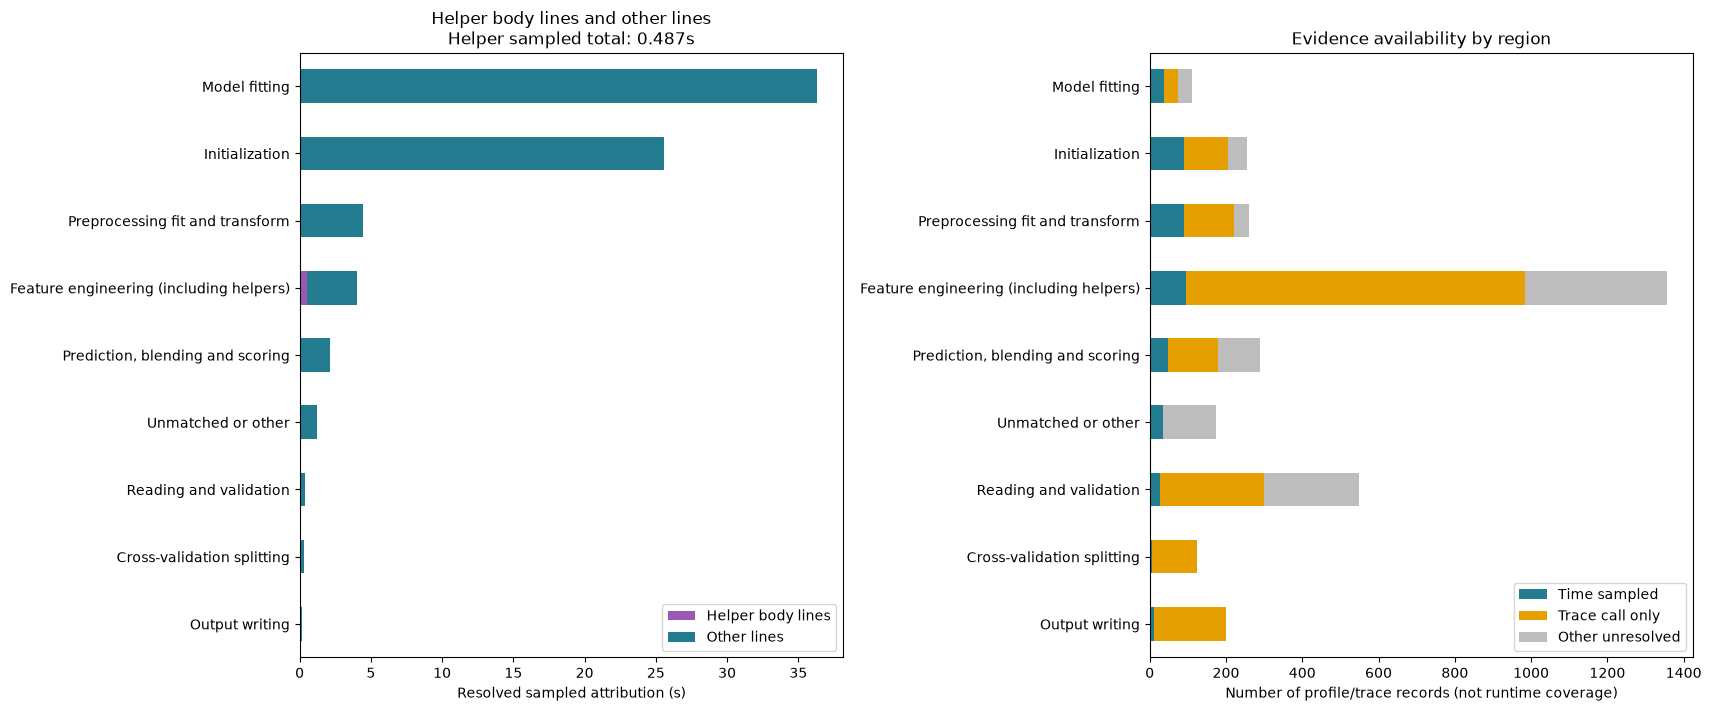

In [9]:
helper_records = lines.assign(line_kind=lines.helper.fillna('').ne('').map({True: 'Helper body lines', False: 'Other lines'}))
helper_attribution = helper_records.groupby(['region', 'line_kind']).attribution_s.sum(min_count=1).unstack().reindex(
    index=region_order, columns=['Helper body lines', 'Other lines'])
coverage_records = lines.assign(evidence_status=lines.apply(
    lambda row: 'Time sampled' if pd.notna(row.attribution_s) else
    'Trace call only' if row.status == 'Call observed in separate trace; profile time unresolved' else
    'Other unresolved', axis=1))
sampling_coverage = pd.crosstab(coverage_records.region, coverage_records.evidence_status).reindex(
    index=region_order, columns=['Time sampled', 'Trace call only', 'Other unresolved'], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout='constrained')
helper_attribution.plot.barh(stacked=True, ax=axes[0], color=['#9b59b6', '#247c91'])
sampling_coverage.plot.barh(stacked=True, ax=axes[1], color=['#247c91', '#e69f00', '#bdbdbd'])
for ax in axes:
    ax.invert_yaxis()
    ax.set_ylabel('')
    ax.legend(loc='lower right')
axes[0].set_xlabel('Resolved sampled attribution (s)')
axes[0].set_title(f'Helper body lines and other lines\nHelper sampled total: {helper_records.loc[helper_records.line_kind.eq("Helper body lines"), "attribution_s"].sum(min_count=1):.3f}s')
axes[1].set_xlabel('Number of profile/trace records (not runtime coverage)')
axes[1].set_title('Evidence availability by region')
figures['helper_sampling_coverage'] = fig
display(fig)
plt.close(fig)
# Validate conservation without converting unresolved time into zero.
assert (helper_attribution.sum(axis=1, min_count=1)-region_totals.attribution_s).abs().dropna().lt(1e-8).all()
assert sampling_coverage.to_numpy().sum() == len(lines)
assert sampling_coverage['Time sampled'].sum() == lines.attribution_s.notna().sum()

**Reviewed interpretation — source hotspots.** Model fitting accounts for 36.324 seconds of sampled source-region attribution, including 22.044 seconds native and 12.369 seconds Python. Initialization accounts for 25.598 seconds. The largest sampled single line is `pipeline_5_3.py:107`, a `classifier.fit` call (2.578 seconds). A call-site attribution includes library execution; Python time at this line does not by itself identify a user-code loop that should be rewritten. Region totals and the broader category totals answer different questions and should not be conflated.


The heatmap shows early pipelines dominated by initialization and later blends by fitting. In the top-15 chart, every displayed hotspot is a model-fitting call, but the components differ: `pipeline_5_3.py:107` is primarily Python-attributed, whereas `pipeline_4_2.py:108` is mostly native. This argues for inspecting the relevant estimator execution before selecting a rewrite strategy.

Helper body lines contribute 0.487 sampled seconds across 15 sampled records, all assigned to feature engineering. There are 175 helper records in total; the remaining records have unresolved time. Across all regions, 441 records have time samples, 1,885 have only separate-trace call evidence, and 995 are otherwise unresolved. These counts expose evidence gaps and do not measure the fraction of runtime captured.


## 5. Feature processing and unselected columns

**Objective:** Inspect string processing, apply calls and features not directly selected for modeling.

**Data and method:** Combine source writes, literal references and sampled attribution. Unselected columns may have indirect dependencies and are not automatically removable.


In [10]:
unused = []
for pipeline in steps:
    tree = ast.parse((root / trajectory / f'{pipeline}.py').read_text())
    selected = set()
    for n in ast.walk(tree):
        if assigned(n, 'cat_cols') or assigned(n, 'num_cols'):
            selected.update(ast.literal_eval(n.value))
    for n in ast.walk(tree):
        if isinstance(n, ast.Assign):
            for target in n.targets:
                if isinstance(target, ast.Subscript) and isinstance(target.value, ast.Name) and target.value.id == 'manifest' and isinstance(target.slice, ast.Constant) and isinstance(target.slice.value, str):
                    column = target.slice.value
                    if column not in selected:
                        refs = sorted({x.lineno for x in ast.walk(tree) if isinstance(x, ast.Constant) and x.value == column and x.lineno != n.lineno})
                        unused.append(dict(pipeline=pipeline, column=column, assignment_line=n.lineno,
                                           other_literal_references=','.join(map(str, refs)),
                                           status='Not selected directly; indirect use possible; removal not established',
                                           source=f'{trajectory}/{pipeline}.py:{n.lineno}'))
unused = pd.DataFrame(unused)
feature = regions[regions.region == 'Feature engineering (including helpers)']
feature_hotspots = hotspots[hotspots.region == 'Feature engineering (including helpers)']
display(feature_hotspots[['pipeline', 'line', 'attribution_s', 'python_s', 'native_s', 'helper', 'code']].head(12))
display(lines[lines.code.str.contains(r'apply|split|fit_transform|predict_proba', regex=True, na=False)][['pipeline', 'line', 'status', 'attribution_s', 'code']].head(20))
display(unused.groupby('pipeline').size().rename('unselected_column_writes').to_frame())
display(unused.head(15))

,pipeline,line,attribution_s,python_s,native_s,helper,code
301,pipeline_1_3,72,0.1764,0.0070,0.1649,,manifest['Group_MeanSpend'] = manifest.groupby('Group')['TotalSpend'].transform('mean')
923,pipeline_3_2,76,0.1749,0.0061,0.1638,,manifest['Family_Size'] = manifest['Surname'].map(surname_counts).fillna(1)
2777,pipeline_6_4,80,0.1726,0.0278,0.1395,,manifest['Cabin_Occupancy'] = manifest['Cabin'].map(cabin_counts).fillna(1)
2207,pipeline_5_4,79,0.1699,0.0005,0.1618,,manifest['Group_MeanSpend'] = manifest.groupby('Group')['TotalSpend'].transform('mean')
795,pipeline_3_1,75,0.1682,0.0028,0.1614,,surname_counts = manifest['Surname'].value_counts().to_dict()
1562,pipeline_4_4,76,0.1679,0.0128,0.1499,,manifest['Family_Size'] = manifest['Surname'].map(surname_counts).fillna(1)
1948,pipeline_5_2,76,0.1622,0.0004,0.1591,,manifest['Family_Size'] = manifest['Surname'].map(surname_counts).fillna(1)
1691,pipeline_4_5,76,0.1536,0.0071,0.1418,,manifest['Family_Size'] = manifest['Surname'].map(surname_counts).fillna(1)
673,pipeline_2_3,79,0.1491,0.0022,0.1434,,manifest['Group_MeanSpend'] = manifest.groupby('Group')['TotalSpend'].transform('mean')
1822,pipeline_5_1,78,0.1453,0.0112,0.1305,,manifest['Cabin_Occupancy'] = manifest['Cabin'].map(cabin_counts).fillna(1)


,pipeline,line,status,attribution_s,code
37,pipeline_1_1,38,Call observed in separate trace; profile time unresolved,NaN,manifest['Group'] = manifest['PassengerId'].apply(lambda x: x.split('_')[0])
38,pipeline_1_1,39,Call observed in separate trace; profile time unresolved,NaN,manifest['Group_Num'] = manifest['PassengerId'].apply(lambda x: int(x.split('_')[1]))
39,pipeline_1_1,40,Call observed in separate trace; profile time unresolved,NaN,manifest['Surname'] = manifest['Name'].apply(lambda x: str(x).split()[-1] if pd.notna(x) and str...
41,pipeline_1_1,42,Time unresolved,NaN,def split_cabin(value):
44,pipeline_1_1,45,Call observed in separate trace; profile time unresolved,NaN,parts = str(value).split('/')
48,pipeline_1_1,49,Call observed in separate trace; profile time unresolved,NaN,cabins = manifest['Cabin'].apply(split_cabin)
52,pipeline_1_1,53,Call observed in separate trace; profile time unresolved,NaN,"manifest['Deck_Side'] = manifest.apply(lambda row: f""{row['Cabin_Deck']}_{row['Cabin_Side']}"" if..."
80,pipeline_1_1,81,Call observed in separate trace; profile time unresolved,NaN,"splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)"
84,pipeline_1_1,85,Observed sample attribution,0.2021,"for (fold, (fit_rows, holdout_rows)) in enumerate(splitter.split(X, y)):"
89,pipeline_1_1,90,Observed sample attribution,0.0351,"X_train_fold = preprocessor.fit_transform(X.iloc[fit_rows], y[fit_rows])"


,unselected_column_writes
pipeline,
pipeline_1_1,19
pipeline_1_2,19
pipeline_1_3,19
pipeline_2_1,12
pipeline_2_2,15
pipeline_2_3,8
pipeline_3_1,2
pipeline_3_2,6
pipeline_3_3,2


,pipeline,column,assignment_line,other_literal_references,status,source
0,pipeline_1_1,Group,38,"65,66,72",Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:38
1,pipeline_1_1,Group_Num,39,,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:39
2,pipeline_1_1,Surname,40,"68,69",Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:40
3,pipeline_1_1,Cabin_Deck,50,53,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:50
4,pipeline_1_1,Cabin_Num,51,"54,56",Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:51
5,pipeline_1_1,Cabin_Side,52,53,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:52
6,pipeline_1_1,Deck_Side,53,,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:53
7,pipeline_1_1,Cabin_Region,54,,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:54
8,pipeline_1_1,Is_Child,55,,Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:55
9,pipeline_1_1,TotalSpend,58,"60,62,63,72,73",Not selected directly; indirect use possible; removal not established,spaceship_titanic_students/pipeline_1_1.py:58


**Reviewed interpretation — feature processing.** Feature engineering including helpers accounts for 4.054 sampled seconds, of which 0.468 seconds are Python and 3.459 seconds native. The largest sampled feature line is a groupby/transform operation in `pipeline_1_3.py:72`, rather than an `apply` call. This evidence supports targeted inspection, but not prioritizing a wholesale Python-to-Rust rewrite. Columns absent from the final feature selection may still support derived features; the unselected-write table is a review aid, not a safe-deletion list.


## 6. Shared computation across the trajectory

**Objective:** Find reuse candidates across all pipelines, including non-adjacent steps.

**Data and method:** Compare conservative AST signatures including dependencies, columns, folds, parameters and seeds. Retain the earliest occurrence; estimate savings only for resolved, non-overlapping regions and ignore cache cost explicitly.


In [11]:
def reuse_tables(infos, lines, steps):
    groups = defaultdict(list)
    for pipeline, info in infos.items():
        for kind, key, positions, conditions in info[3]:
            groups[(kind, key)].append((pipeline, positions, conditions))
    candidates, occurrences = [], []
    for (kind, key), members in sorted(groups.items()):
        if len(members) < 2:
            continue
        cid = f'C{len(candidates) + 1:03}'
        amounts = []
        ordered = sorted(members, key=lambda m: (steps[m[0]], m[0], m[1][0]))
        for index, (pipeline, positions, conditions) in enumerate(ordered):
            subset = lines[(lines.pipeline == pipeline) & lines.source_matched & lines.line.isin(positions)]
            value = subset.attribution_s.sum(min_count=1)
            # Every code line's profile text must match before using block timing.
            main_rows = lines[(lines.pipeline == pipeline) & lines.profile_source.str.endswith(f'/{pipeline}.py') & lines.line.isin(positions)]
            if not main_rows.source_matched.all():
                value = float('nan')
            amounts.append(value)
            occurrences.append(dict(candidate_id=cid, kind=kind, pipeline=pipeline, step=steps[pipeline],
                                    start_line=min(positions), end_line=max(positions),
                                    lines=','.join(map(str, positions)), attribution_s=value,
                                    retain=index == 0, source=f'{pipeline}.py:{min(positions)}',
                                    status='Attribution available' if pd.notna(value) else 'Time unresolved'))
        resolved = all(pd.notna(x) for x in amounts)
        overlapping = kind == 'Upstream probabilities for threshold variants'
        candidates.append(dict(candidate_id=cid, kind=kind, occurrences=len(members),
                               pipelines=';'.join(dict.fromkeys(m[0] for m in ordered)),
                               steps=';'.join(map(str, sorted({steps[m[0]] for m in members}))),
                               signature=hashlib.sha256(key.encode()).hexdigest(),
                               evidence='Source-equivalent candidate; historical inputs and cache compatibility unverified', conditions=members[0][2],
                               retained=f'{ordered[0][0]}:{ordered[0][1][0]}',
                               scenario_saved_s=sum(amounts) - amounts[0] if resolved and not overlapping else None,
                               estimate_note='Overlaps preprocessing/model regions; savings not counted' if overlapping else
                               'Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound' if resolved else 'Unresolved regions present; do not substitute zero'))
    return pd.DataFrame(candidates), pd.DataFrame(occurrences)

In [12]:
candidates, occurrences = reuse_tables(infos, lines, steps)
display(candidates[['candidate_id', 'kind', 'occurrences', 'steps', 'scenario_saved_s', 'estimate_note']])
model_candidates = candidates[candidates.kind == 'Model training and prediction']
display(model_candidates[['candidate_id', 'pipelines', 'conditions', 'scenario_saved_s']])
display(occurrences[['candidate_id', 'pipeline', 'step', 'start_line', 'end_line', 'attribution_s', 'retain', 'status']].head(20))

,candidate_id,kind,occurrences,steps,scenario_saved_s,estimate_note
0,C001,Feature engineering,3,1,NaN,Unresolved regions present; do not substitute zero
1,C002,Feature engineering,22,2;3;4;5;6;7,3.0186,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
2,C003,Model training and prediction,2,4;6,0.2872,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
3,C004,Model training and prediction,5,3;6;7,0.0844,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
4,C005,Model training and prediction,2,5;6,0.8994,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
5,C006,Model training and prediction,7,5;6;7,11.3439,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
6,C007,Model training and prediction,7,4;6;7,10.1752,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
7,C008,Model training and prediction,2,4;6,0.4624,Assumes compatibility and zero cache cost; retains earliest occurrence; not a verified upper bound
8,C009,Reading and validation,25,1;2;3;4;5;6;7,NaN,Unresolved regions present; do not substitute zero
9,C010,Upstream probabilities for threshold variants,4,6;7,NaN,Overlaps preprocessing/model regions; savings not counted


,candidate_id,pipelines,conditions,scenario_saved_s
2,C003,pipeline_4_5;pipeline_6_4,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",0.2872
3,C004,pipeline_3_1;pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",0.0844
4,C005,pipeline_5_4;pipeline_6_4,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",0.8994
5,C006,pipeline_5_1;pipeline_6_1;pipeline_6_2;pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",11.3439
6,C007,pipeline_4_2;pipeline_6_1;pipeline_6_2;pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",10.1752
7,C008,pipeline_4_4;pipeline_6_4,"Matching feature prefix, preprocessing, folds, model parameters and seeds; only local probabilit...",0.4624


,candidate_id,pipeline,step,start_line,end_line,attribution_s,retain,status
0,C001,pipeline_1_1,1,37,73,NaN,True,Time unresolved
1,C001,pipeline_1_2,1,37,73,0.1206,False,Attribution available
2,C001,pipeline_1_3,1,37,73,0.2543,False,Attribution available
3,C002,pipeline_2_1,2,37,80,0.1417,True,Attribution available
4,C002,pipeline_2_2,2,37,80,0.1799,False,Attribution available
5,C002,pipeline_2_3,2,37,80,0.1745,False,Attribution available
6,C002,pipeline_3_1,3,37,80,0.2378,False,Attribution available
7,C002,pipeline_3_2,3,37,80,0.2602,False,Attribution available
8,C002,pipeline_3_3,3,37,80,0.2343,False,Attribution available
9,C002,pipeline_4_1,4,37,80,0.1048,False,Attribution available


**Reviewed interpretation — reuse candidates.** The source comparison identifies 13 candidate groups. The two largest resolved model groups correspond to the forest first used in `pipeline_5_1` and the histogram model first used in `pipeline_4_2`; both recur in later blends and threshold variants. Their individual zero-cache-cost scenarios remove 11.344 and 10.175 attributed seconds respectively. The source in `pipeline_6_3.py:117–134` independently instantiates and fits those models inside each fold. This is a concrete reason to validate cross-step probability reuse. The values are conditional scenarios, not measured savings; threshold-upstream groups overlap these computations and must not be added again. Candidate IDs are generated from grouping order; use kind and pipeline membership when comparing exports from different implementations.


## 7. Threshold variants and prediction artifacts

**Objective:** Separate probability computation from scoring thresholds.

**Data and method:** Compare probability signatures and hashes of existing prediction files. Byte equality is an artifact clue, not proof of historical reuse; execution-summary accuracy remains separate.


In [13]:
def artifact_clues(root, trajectory, pipelines):
    """Byte equality is an artifact clue only, never proof of historical reuse."""
    records = []
    for pipeline in pipelines:
        for name in ['oof_predictions.csv', 'test_probabilities.csv']:
            path = root / trajectory / 'results' / pipeline / name
            records.append(dict(pipeline=pipeline, artifact=name, source=str(path.relative_to(root)),
                                sha256=hashlib.sha256(path.read_bytes()).hexdigest() if path.exists() else '',
                                status='Existing artifact clue; not linked to profile execution' if path.exists() else 'Missing'))
    return pd.DataFrame(records)

In [14]:
family = candidates[candidates.kind == 'Upstream probabilities for threshold variants']
clues = artifact_clues(root, trajectory, steps)
artifact_groups = clues[clues.sha256 != ''].groupby(['artifact', 'sha256']).agg(
    pipelines=('pipeline', lambda values: ';'.join(values)), count=('pipeline', 'size')).reset_index()
matching_artifacts = artifact_groups[artifact_groups['count'] > 1]
execution = pd.DataFrame(json.loads((root / trajectory / 'results/summary.json').read_text()))
execution['interpretation'] = 'Separate execution summary; no identity linkage or speedup comparison with profiles/predictions'
display(family[['candidate_id', 'pipelines', 'estimate_note']])
display(matching_artifacts[['artifact', 'pipelines', 'count']])
display(execution)

,candidate_id,pipelines,estimate_note
9,C010,pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,Overlaps preprocessing/model regions; savings not counted


,artifact,pipelines,count
16,oof_predictions.csv,pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,4
37,test_probabilities.csv,pipeline_6_3;pipeline_7_1;pipeline_7_2;pipeline_7_3,4


,pipeline_id,cv_accuracy,seconds,rank,interpretation
0,pipeline_4_3,0.8126,3.2776,1,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
1,pipeline_4_4,0.8110,2.4875,2,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
2,pipeline_4_2,0.8109,2.8364,3,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
3,pipeline_6_2,0.8107,4.2670,4,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
4,pipeline_6_3,0.8100,4.3731,5,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
5,pipeline_7_2,0.8100,4.3456,5,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
6,pipeline_6_4,0.8080,3.7279,7,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
7,pipeline_4_1,0.8078,2.5920,8,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
8,pipeline_5_4,0.8072,2.9363,9,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions
9,pipeline_7_1,0.8071,4.3533,10,Separate execution summary; no identity linkage or speedup comparison with profiles/predictions


**Reviewed interpretation — artifact clues.** `pipeline_6_3`, `pipeline_7_1`, `pipeline_7_2` and `pipeline_7_3` form a source-equivalent upstream-probability group, and their existing OOF files and test-probability files respectively match byte for byte. This supports testing probability reuse while varying the decision threshold. It does not establish that the files came from the profiled execution, nor does it prove that future reuse preserves inputs, row order, fold identity or random state.


## 8. Memory, allocation and copying

**Objective:** Identify resource signals alongside time hotspots.

**Data and method:** Inspect process peaks, cumulative line allocations and raw copy rates separately. None establishes actual parallel memory or copying bottlenecks.


In [15]:
memory_ranking = pipelines.sort_values('max_footprint_mb', ascending=False)
allocation_hotspots = lines.sort_values('malloc_mb', ascending=False)
display(memory_ranking[['pipeline', 'step', 'max_footprint_mb', 'elapsed_time_sec']].head(10))
display(allocation_hotspots[['pipeline', 'line', 'region', 'attribution_s', 'malloc_mb', 'peak_mb', 'copy_mb_s_raw']].head(12))

,pipeline,step,max_footprint_mb,elapsed_time_sec
15,pipeline_5_2,5,128.8298,3.2630
18,pipeline_6_1,6,128.5035,4.4422
22,pipeline_7_1,7,127.7205,4.2368
24,pipeline_7_3,7,127.1614,4.4475
20,pipeline_6_3,6,125.8766,4.2889
16,pipeline_5_3,5,124.6841,4.2578
19,pipeline_6_2,6,122.2580,4.8994
14,pipeline_5_1,5,120.5969,3.0774
21,pipeline_6_4,6,120.2191,3.5595
10,pipeline_4_2,4,119.1728,2.6595


,pipeline,line,region,attribution_s,malloc_mb,peak_mb,copy_mb_s_raw
1465,pipeline_4_3,108,Model fitting,2.2794,752.5512,30.6711,12.5773
2507,pipeline_6_2,108,Model fitting,1.6134,672.6825,122.2580,3.1998
2364,pipeline_6_1,108,Model fitting,1.6576,540.0538,23.8974,1.9906
3285,pipeline_7_3,120,Model fitting,1.5521,517.5072,22.2396,3.9086
2662,pipeline_6_3,120,Model fitting,1.6237,479.8179,21.6747,9.7500
2975,pipeline_7_1,120,Model fitting,1.7177,472.9000,25.6132,12.9320
3130,pipeline_7_2,120,Model fitting,1.5797,470.0887,25.7789,4.0255
1336,pipeline_4_2,108,Model fitting,1.9100,451.2983,31.4327,4.9915
2107,pipeline_5_3,107,Model fitting,2.5782,183.3987,124.6841,29.5805
2519,pipeline_6_2,120,Model fitting,1.9952,117.0053,83.9213,15.1955


**Reviewed interpretation — memory.** The largest observed process peak is 128.830 MB (`pipeline_5_2`). High cumulative allocations occur at model-fitting lines, including approximately 752.551 MB at `pipeline_4_3.py:108`; this is not simultaneous residency. The process-peak plot shows relatively similar individual footprints rather than one extreme memory outlier. Raw copy rates remain exploratory; the evidence does not establish that data movement is the dominant runtime cost.


## 9. Scheduling and initialization scenarios

**Objective:** Estimate theoretical scheduling and initialization opportunities.

**Data and method:** Respect step barriers. Compare sequential and unlimited-worker schedules, then simulate finite workers with memory reservations. Apply Amdahl sensitivity to an assumed removable fraction of setup; actual removability is unknown.


In [16]:
display(manifest['execution'])
ideal = summary.ideal_step_s.sum()
setup_s = totals.set_index('category').loc['setup', 'total_s']
setup_fraction = setup_s / total
parallel_scenarios = pd.DataFrame([
    {'scenario': 'Sequential profile sum', 'seconds': total, 'theoretical_ratio': 1.0},
    {'scenario': 'Ideal within-step parallelism', 'seconds': ideal, 'theoretical_ratio': total / ideal},
])
amdahl = pd.DataFrame([
    {'scenario': 'Setup twice as fast', 'setup_fraction': setup_fraction,
     'theoretical_ratio': 1 / (1 - setup_fraction + setup_fraction / 2)},
    {'scenario': 'Setup entirely eliminated', 'setup_fraction': setup_fraction,
     'theoretical_ratio': 1 / (1 - setup_fraction)},
])
display(summary[['pipelines', 'total_s', 'ideal_step_s']])
display(parallel_scenarios)
display(amdahl)

{'step_order': 'ascending; barrier between steps',
 'within_step': 'independent; any order or concurrent',
 'artifact_dependencies': 'none; every script is standalone',
 'winner_selection': 'none; replay all fixed candidates'}

,pipelines,total_s,ideal_step_s
step,,,
1,3,6.0845,2.2948
2,3,6.8503,2.5682
3,3,5.8472,2.0874
4,5,12.8470,3.3213
5,4,13.3743,4.2578
6,4,17.1899,4.8994
7,3,12.8778,4.4475


,scenario,seconds,theoretical_ratio
0,Sequential profile sum,75.0710,1.0000
1,Ideal within-step parallelism,23.8764,3.1442


,scenario,setup_fraction,theoretical_ratio
0,Setup twice as fast,0.3410,1.2055
1,Setup entirely eliminated,0.3410,1.5174


**Reviewed interpretation — theoretical opportunities.** Summing the longest pipeline in each step yields 23.876 seconds under unlimited resources, no contention, constant task durations and zero overhead, a 3.14× ratio to the sequential profile sum. Setup constitutes 34.1% of that sum; making all of this attributed work twice as fast gives an Amdahl ratio of 1.21×, and removing it entirely gives a limiting ratio of 1.52×. Actual startup work may not be removable, and neither ratio is a measured optimization result.


### Additional visual evidence and sensitivity models

The following charts complete the five analysis areas. Memory reservations use individual observed peaks as a scheduling assumption, not measured concurrent RSS. The scheduler uses longest-first greedy placement, constant task durations, zero scheduling overhead and no contention. It is not an optimal scheduler or a forecast. Setup eligibility is varied because existing profiles cannot identify the removable fraction.


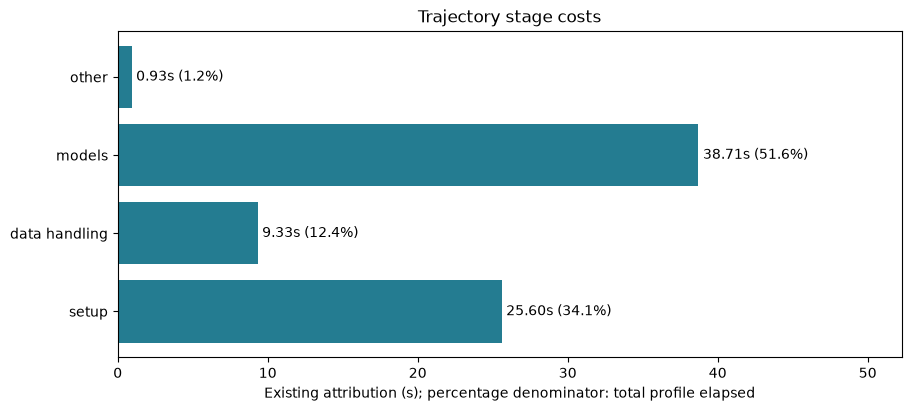

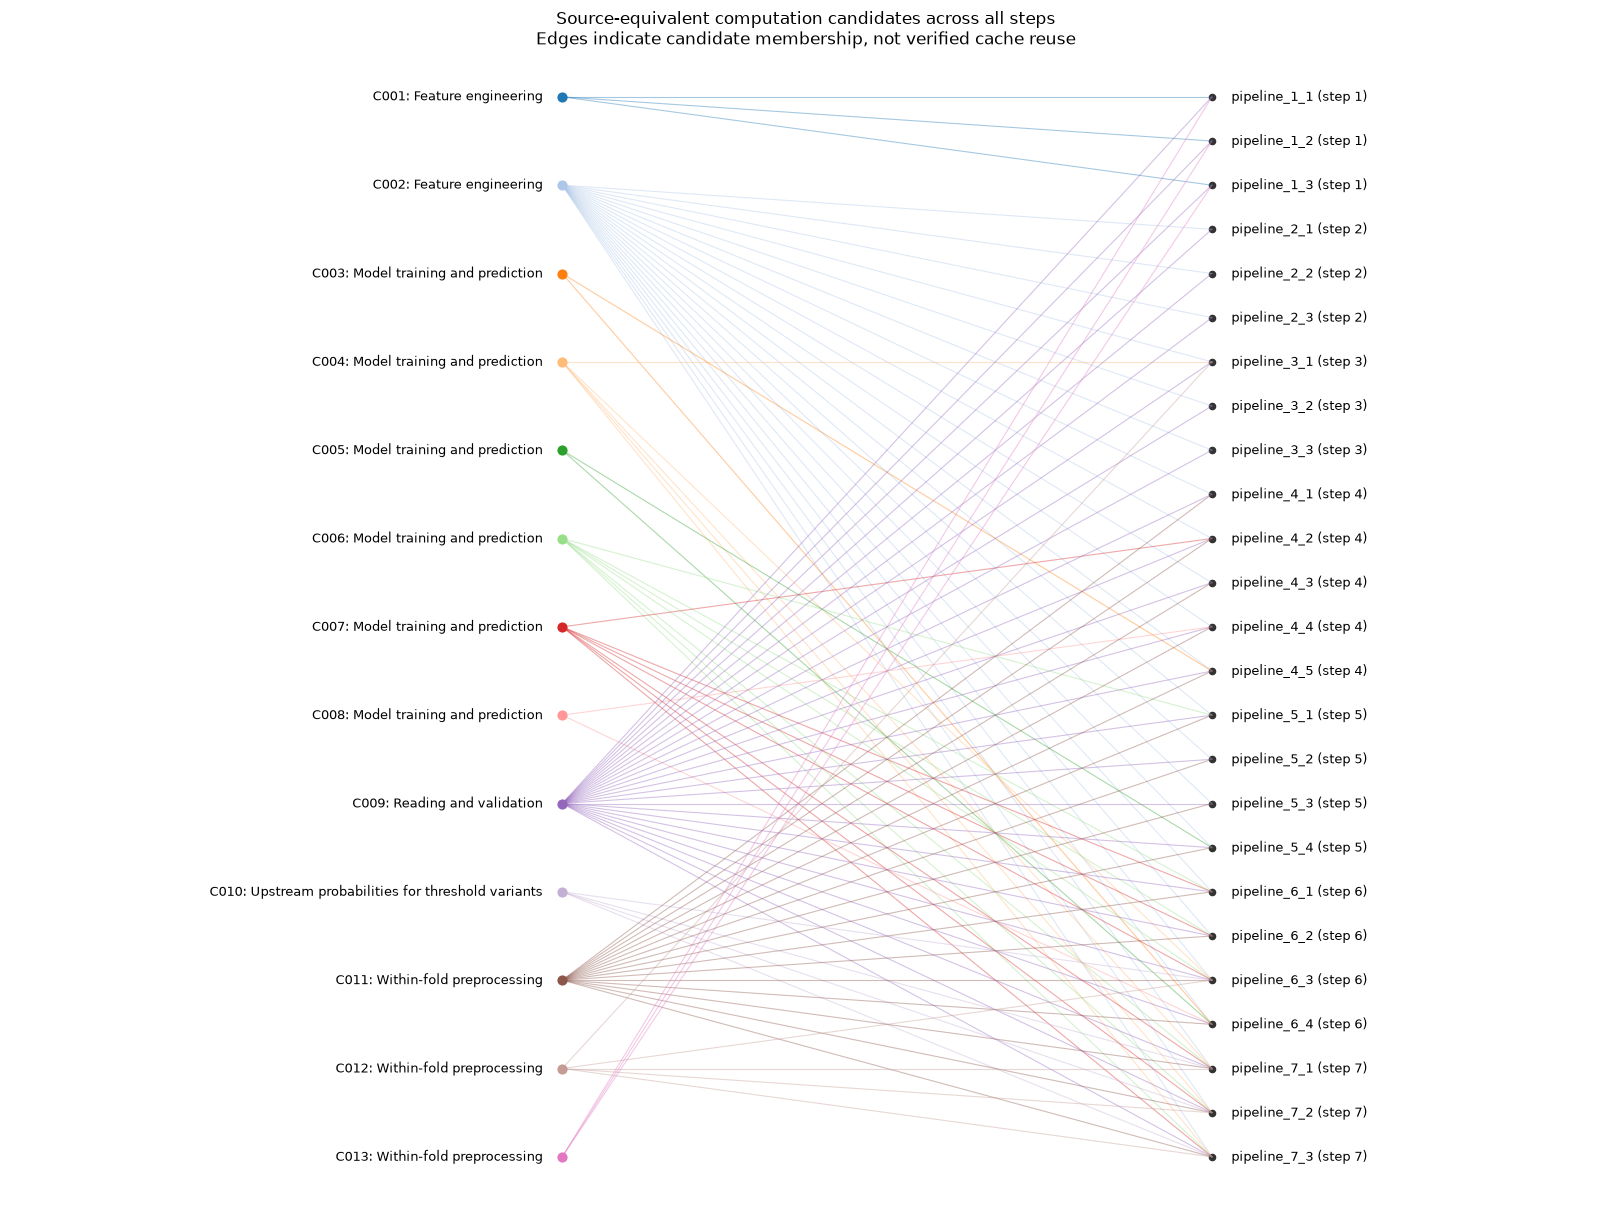

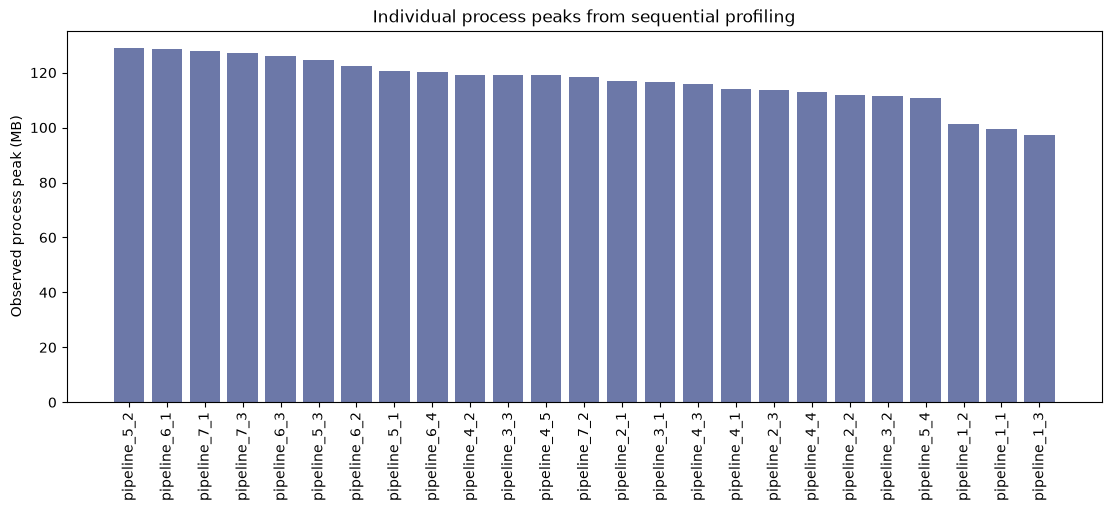

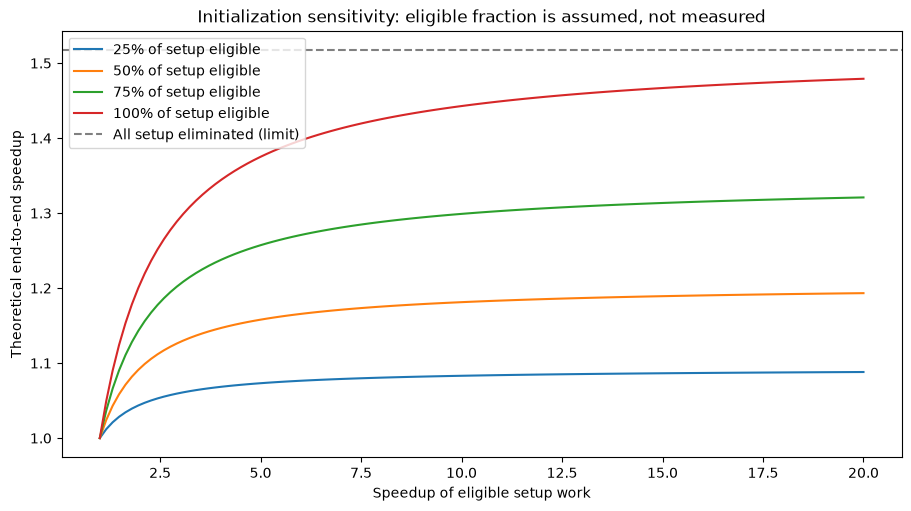

,pipeline,line,code,attribution_s
5,pipeline_1_1,6,from sklearn.compose import ColumnTransformer,1.4202
350,pipeline_2_1,6,from sklearn.compose import ColumnTransformer,1.0683
120,pipeline_1_2,6,from sklearn.compose import ColumnTransformer,1.0631
474,pipeline_2_2,6,from sklearn.compose import ColumnTransformer,1.0296
979,pipeline_3_3,6,from sklearn.compose import ColumnTransformer,0.8876
600,pipeline_2_3,6,from sklearn.compose import ColumnTransformer,0.8733
726,pipeline_3_1,6,from sklearn.compose import ColumnTransformer,0.7513
1621,pipeline_4_5,6,from sklearn.compose import ColumnTransformer,0.7498
235,pipeline_1_3,6,from sklearn.compose import ColumnTransformer,0.7155
2134,pipeline_5_4,6,from sklearn.compose import ColumnTransformer,0.7101


,workers,memory_budget_mb,modeled_seconds,modeled_ratio
0,1,192.0000,75.0710,1.0000
1,1,256.0000,75.0710,1.0000
2,1,512.0000,75.0710,1.0000
3,1,inf,75.0710,1.0000
4,2,192.0000,75.0710,1.0000
5,2,256.0000,43.2317,1.7365
6,2,512.0000,43.2317,1.7365
7,2,inf,43.2317,1.7365
8,3,192.0000,75.0710,1.0000
9,3,256.0000,43.2317,1.7365


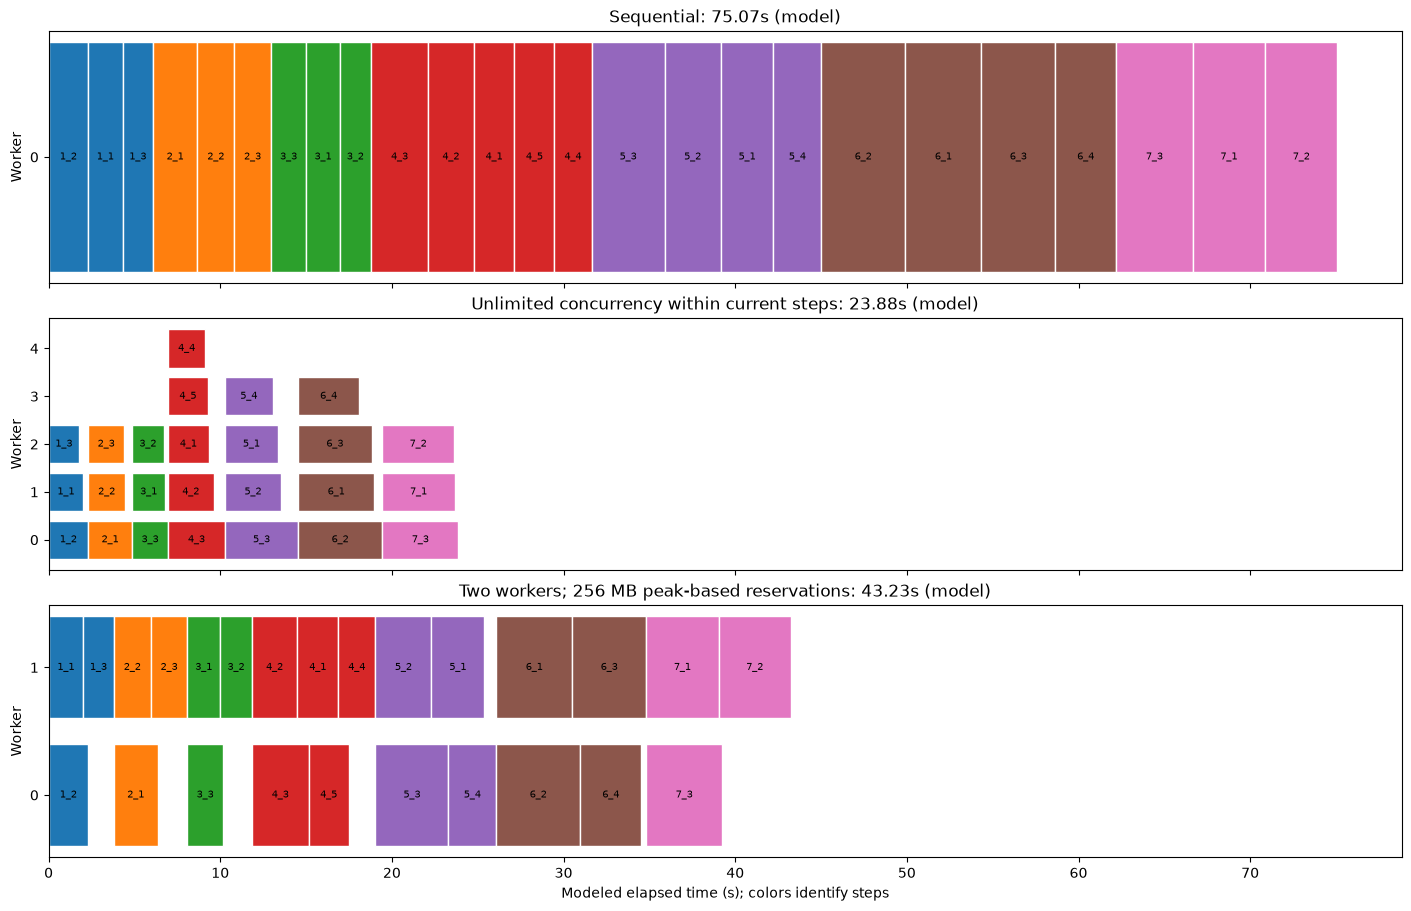

In [17]:
# Stage totals and attribution coverage.
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.barh(totals.category, totals.total_s, color='#247c91')
for i, row in enumerate(totals.itertuples()):
    ax.text(row.total_s + .3, i, f'{row.total_s:.2f}s ({row.share_of_profile_elapsed:.1%})', va='center')
ax.set_xlim(0, totals.total_s.max() * 1.35)
ax.set_xlabel('Existing attribution (s); percentage denominator: total profile elapsed')
ax.set_title('Trajectory stage costs')
figures['stage_totals'] = fig
display(fig); plt.close(fig)

# Bipartite relationship diagram: candidate groups connect source-equivalent occurrences.
fig, ax = plt.subplots(figsize=(16, 12), layout='constrained')
positions = {p: len(pipelines)-1-i for i,p in enumerate(pipelines.pipeline)}
for i,row in enumerate(candidates.itertuples()):
    y = (len(pipelines)-1) * (1-i/max(1,len(candidates)-1))
    color = plt.get_cmap('tab20')(i % 20)
    ax.scatter(0,y,color=color,s=40)
    ax.text(-.03,y,f'{row.candidate_id}: {row.kind}',ha='right',va='center',fontsize=9)
    for p in row.pipelines.split(';'):
        ax.plot([0,1],[y,positions[p]],color=color,alpha=.4,linewidth=.8)
for p,y in positions.items():
    ax.scatter(1,y,color='#333333',s=20)
    ax.text(1.03,y,f'{p} (step {steps[p]})',va='center',fontsize=9)
ax.set_xlim(-.85,1.6); ax.set_ylim(-1,len(pipelines)); ax.axis('off')
ax.set_title('Source-equivalent computation candidates across all steps\nEdges indicate candidate membership, not verified cache reuse')
figures['shared_computation_graph'] = fig
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
ax.bar(memory_ranking.pipeline, memory_ranking.max_footprint_mb,color='#6c78a8')
ax.tick_params(axis='x',rotation=90); ax.set_ylabel('Observed process peak (MB)')
ax.set_title('Individual process peaks from sequential profiling')
figures['process_memory_peaks'] = fig
display(fig); plt.close(fig)

import numpy as np
setup_speedups = np.linspace(1,20,120)
fig, ax = plt.subplots(figsize=(9,5),layout='constrained')
for removable in [.25,.5,.75,1.0]:
    effective_fraction = setup_fraction * removable
    ax.plot(setup_speedups,1/(1-effective_fraction+effective_fraction/setup_speedups),label=f'{removable:.0%} of setup eligible')
ax.axhline(1/(1-setup_fraction),linestyle='--',color='gray',label='All setup eliminated (limit)')
ax.set_xlabel('Speedup of eligible setup work'); ax.set_ylabel('Theoretical end-to-end speedup')
ax.set_title('Initialization sensitivity: eligible fraction is assumed, not measured')
ax.legend(); figures['initialization_sensitivity'] = fig
display(fig); plt.close(fig)
setup_lines = lines[lines.region.eq('Initialization')].sort_values('attribution_s',ascending=False)
display(setup_lines[['pipeline','line','code','attribution_s']].head(15))

# Finite-worker, memory-reservation list scheduling model. It does not execute tasks.
def simulate_schedule(worker_count, memory_budget_mb=float('inf')):
    if worker_count < 1 or memory_budget_mb <= 0:
        raise ValueError('Workers and memory budget must be positive')
    records, barrier = [], 0.0
    for step, group in pipelines.groupby('step', sort=True):
        pending = list(group.sort_values('elapsed_time_sec',ascending=False).itertuples())
        if any(p.max_footprint_mb > memory_budget_mb for p in pending):
            return None
        active=[]; now=barrier
        while pending or active:
            active=[a for a in active if a['end_s'] > now + 1e-9]
            free=[w for w in range(worker_count) if all(a['worker'] != w for a in active)]
            for worker in free:
                used=sum(a['reserved_mb'] for a in active)
                fit=next((i for i,p in enumerate(pending) if used+p.max_footprint_mb <= memory_budget_mb),None)
                if fit is None: continue
                p=pending.pop(fit)
                rec=dict(pipeline=p.pipeline,step=step,worker=worker,start_s=now,
                         end_s=now+p.elapsed_time_sec,reserved_mb=p.max_footprint_mb)
                records.append(rec);active.append(rec)
            if active: now=min(a['end_s'] for a in active)
            elif pending: raise RuntimeError('Schedule made no progress')
        barrier=max(r['end_s'] for r in records)
    return pd.DataFrame(records)

schedule_rows=[]
for workers in [1,2,3,5]:
    for budget in [192,256,512,float('inf')]:
        schedule=simulate_schedule(workers,budget)
        seconds=schedule.end_s.max() if schedule is not None else None
        schedule_rows.append(dict(workers=workers,memory_budget_mb=budget,modeled_seconds=seconds,
                                  modeled_ratio=total/seconds if seconds else None))
scheduling_scenarios=pd.DataFrame(schedule_rows)
display(scheduling_scenarios)
fig, axes=plt.subplots(3,1,figsize=(14,9),layout='constrained',sharex=True)
for ax,(workers,budget,title) in zip(axes,[(1,float('inf'),'Sequential'),(5,float('inf'),'Unlimited concurrency within current steps'),(2,256,'Two workers; 256 MB peak-based reservations')]):
    schedule=simulate_schedule(workers,budget)
    for row in schedule.itertuples():
        ax.barh(row.worker,row.end_s-row.start_s,left=row.start_s,color=plt.get_cmap('tab10')(row.step-1),edgecolor='white')
        ax.text((row.start_s+row.end_s)/2,row.worker,row.pipeline.removeprefix('pipeline_'),ha='center',va='center',fontsize=7)
    ax.set_yticks(range(workers));ax.set_ylabel('Worker');ax.set_title(f'{title}: {schedule.end_s.max():.2f}s (model)')
axes[-1].set_xlabel('Modeled elapsed time (s); colors identify steps')
figures['schedule_comparison'] = fig
display(fig);plt.close(fig)
assert abs(simulate_schedule(1).end_s.max()-total) < 1e-8
assert abs(simulate_schedule(5).end_s.max()-ideal) < 1e-8
for workers,budget in [(2,256),(3,192),(5,512)]:
    schedule=simulate_schedule(workers,budget)
    for t in schedule.start_s:
        running=schedule[(schedule.start_s<=t)&(schedule.end_s>t+1e-9)]
        assert len(running)<=workers and running.reserved_mb.sum() <= budget+1e-8
    assert all(schedule[schedule.step==s].start_s.min() >= schedule[schedule.step<s].end_s.max()-1e-8 for s in sorted(steps.values()) if s>1)


**Reviewed interpretation — additional charts and constrained scenarios.** The region heatmap confirms the transition from early initialization hotspots to later fitting hotspots. The shared-computation diagram shows opportunities spanning non-adjacent steps, not just neighboring candidates. Initialization samples repeatedly point to the first sklearn import, for example `pipeline_1_1.py:6`; that line includes library loading and is not evidence that `ColumnTransformer` itself is inefficient. The sensitivity curves show that a small eligible setup fraction imposes a low ceiling even with large local acceleration. Existing data cannot measure the eligible fraction, so no import cost is declared fully removable.

In the greedy scheduling model, two workers with a 256 MB reservation budget take 43.232 seconds (1.74× modeled ratio); three workers with 512 MB take 29.931 seconds (2.51×); five workers with 512 MB take 25.047 seconds (3.00×). A 192 MB budget serializes the modeled tasks. These budgets are illustrative task-reservation budgets, not machine-RAM recommendations: the model reserves observed individual process peaks, omits system overhead and shared-memory effects, and assumes durations remain constant. The Gantt chart illustrates step barriers and idle slots. Actual parallel speedup and RSS require execution measurements.


## 10. Evidence gaps and validation experiments

The checklist records experiments needed to verify reuse, initialization removability, concurrency and local rewrites. These are not performed by this notebook. The assistant-reviewed interpretation follows the computed evidence.


In [18]:
validation_plan = pd.DataFrame([
    ('Reuse', 'Historical input, fold, parameter and environment identity', 'Validate one shared model output, then measure cache reads/writes and end-to-end time'),
    ('Persistent workers', 'Removable setup fraction and safe process state reuse', 'Compare cold and warm workers; check predictions, seeds, repeated timings and RSS'),
    ('Parallel execution', 'Contention, thread oversubscription and actual concurrent memory', 'Compare one and two workers with bounded library threads'),
    ('Local rewrites', 'Stable Python hotspots and indirect feature dependencies', 'Check missing values, parsing edge cases and downstream equivalence before timing'),
], columns=['direction', 'missing_evidence', 'minimum_experiment'])
display(validation_plan)


,direction,missing_evidence,minimum_experiment
0,Reuse,"Historical input, fold, parameter and environment identity","Validate one shared model output, then measure cache reads/writes and end-to-end time"
1,Persistent workers,Removable setup fraction and safe process state reuse,"Compare cold and warm workers; check predictions, seeds, repeated timings and RSS"
2,Parallel execution,"Contention, thread oversubscription and actual concurrent memory",Compare one and two workers with bounded library threads
3,Local rewrites,Stable Python hotspots and indirect feature dependencies,"Check missing values, parsing edge cases and downstream equivalence before timing"


**Reviewed interpretation — experiment priorities.** First validate one cross-step model reuse candidate, because the source identifies substantial repeated training with explicit parameters and fold dependencies. Next test persistent workers, supported by substantial repeated initialization. Then test limited within-step concurrency with controlled library threads, using the modeled schedules only to select experiments. These directions interact, so their benefits cannot be added independently. Local vectorization, representation changes and unused-feature removal remain secondary until dependency and hotspot stability checks justify them. Existing evidence cannot establish causal speedups, safe caching, warm-process isolation or optimized prediction quality.


## 11. Export and integrity checks

**Objective:** Save reproducible tables and figures without changing source evidence.

**Data and method:** Verify unique line ownership, unresolved statuses, non-overlapping candidates and unchanged input hashes. Export the computed tables and all figures.


In [19]:
assert not lines.duplicated(['pipeline', 'profile_source', 'line']).any()
assert not (lines.attribution_s == 0).any()
assert lines.loc[lines.attribution_s.isna(), 'status'].str.contains('time unresolved', case=False).all()
seen = set()
for row in occurrences.itertuples():
    if row.kind == 'Upstream probabilities for threshold variants':
        continue
    keys = {(row.pipeline, int(line)) for line in row.lines.split(',')}
    assert not keys & seen, f'Candidate regions counted twice: {row.candidate_id}'
    seen.update(keys)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in input_hashes.items())
output.mkdir(parents=True, exist_ok=True)
tables = {
    'pipeline_ranking': ranking, 'category_summary': totals, 'step_summary': summary.reset_index(),
    'step_categories': step_categories, 'line_attribution': lines, 'hotspots': hotspots, 'regions': regions,
    'shared_candidates': candidates, 'shared_occurrences': occurrences, 'artifact_clues': clues,
    'execution_summary_context': execution, 'pipeline_conclusions': conclusions,
    'validation_plan': validation_plan, 'scheduling_scenarios': scheduling_scenarios,
    'initialization_lines': setup_lines,
    'region_matrix': region_matrix.rename_axis('pipeline').reset_index(),
    'region_components': region_totals.reset_index(),
    'top_source_lines': source_reference,
    'helper_attribution': helper_attribution.reset_index(),
    'sampling_coverage': sampling_coverage.reset_index(), 'unused_features': unused,
}
for name, frame in tables.items():
    frame.to_csv(output / f'{name}.csv', index=False)
for name, fig in figures.items():
    fig.savefig(output / f'{name}.png', dpi=150)
display(pd.DataFrame([{'file': f'{name}.csv', 'rows': len(frame)} for name, frame in tables.items()]))
print(f'All checks passed. Output directory: {output}')

All checks passed. Output directory: /Users/tue/Documents/10_Projects/deai-pro/results/spaceship_titanic_students/bottleneck_analysis/notebook


,file,rows
0,pipeline_ranking.csv,25
1,category_summary.csv,4
2,step_summary.csv,7
3,step_categories.csv,28
4,line_attribution.csv,3321
5,hotspots.csv,441
6,regions.csv,225
7,shared_candidates.csv,13
8,shared_occurrences.csv,111
9,artifact_clues.csv,50


**Reviewed interpretation — reproducibility.** All analytical cells completed, exporting 21 tables and 12 figures. Input-hash, unique-attribution, unresolved-time and non-overlapping-candidate checks passed, as did scheduling conservation and resource checks. No pipeline or profiler was replayed. These English interpretations were written by the assistant after reviewing this run's computed tables, source snippets and chart images; they are not automatically regenerated by executing the notebook.
